# Implementación CARP para recolección de residuos

## 1. Datos de la instancia


- \(P=2\): número de vehículos.
- \(W=15000\): capacidad de cada vehículo.
- \(n=10\): número de nodos internos.
- \(m=7\): número de arcos que requieren recolectar basura.

Los arcos requeridos son

$$
A_R=\{(1,2),(3,4),(2,5),(5,6),(7,8),(9,10),(10,6)\}.
$$

### Observación importante sobre $(L$)

Con las demandas utilizadas en este cuaderno,

$$
5000,\;5000,\;5000,\;2500,\;2500,\;2000,\;2000,
$$

y $(W=15000)$, la cota construida a partir de la capacidad da

$$
\ell=3,\qquad
L_{\text{cap}}=\left\lceil\frac{7}{3}\right\rceil=3.
$$

Sin embargo, la formulación completa del paper considera (P) viajes iniciales y (P) viajes finales. Con (P=2) se necesitan al menos

$
2P=4
$

índices de viaje. Por ello, **sin cambiar las demandas ni la capacidad**, se usa para la implementación la cota más holgada

$
L=\max\{L_{\text{cap}},2P\}=4.
$



In [1]:

import math
from itertools import combinations

import gurobipy as gp
from gurobipy import GRB
import networkx as nx
import matplotlib.pyplot as plt



A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.0.2 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "/Library/Frameworks/Python.framework/Versions/3.9/lib/python3.9/runpy.py", line 197, in _run_module_as_main
    return _run_code(code, main_globals, None,
  File "/Library/Frameworks/Python.framework/Versions/3.9/lib/python3.9/runpy.py", line 87, in _run_code
    exec(code, run_globals)
  File "/Users/luistorres/.Envs/gurobienv/lib/python3.9/site-packages/ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "/Users/luistorres/.Envs/gurobienv/lib/python3.9/site-packages/traitlets/config/

AttributeError: _ARRAY_API not found

ImportError: numpy.core.multiarray failed to import


## 1. Definición del grafo

Usaremos:

- \(V\): conjunto de todos los nodos.
- \(U\): nodos internos de la zona de recolección.
- \(A\): conjunto de todos los arcos que pueden recorrerse.
- \(A_R\subseteq A\): arcos que requieren servicio.

Donde,

- `s` representa la **base de la cuadrilla**;
- `t` representa la **instalación de descarga o reciclaje**;
- los nodos `1,...,10` representan intersecciones internas.


In [29]:

# Nodos internos
U = [str(i) for i in range(1,11)]

# Todos los nodos
V = ["s"] + U + ["t"]

# Conjunto de arcos
A = gp.tuplelist([
    ("s","1"), ("1","s"), ("s","3"),
    ("1","2"), ("2","1"),
    ("2","3"),
    ("3","4"), ("4","3"),
    ("4","5"),
    ("2","5"), ("5","2"),
    ("5","6"), ("6","5"),
    ("6","7"), ("7","6"),
    ("7","8"), ("8","7"),
    ("8","9"), ("9","8"),
    ("9","10"), ("10","9"),
    ("10","6"), ("6","10"),
    ("2","t"), ("t","8"),
    ("8","t"), ("9","t"), ("6", "t")
])

# Arcos que requieren recolección
AR = gp.tuplelist([
    ("1","2"),
    ("3","4"),
    ("2","5"),
    ("5","6"),
    ("7","8"),
    ("9","10"),
    ("10","6")
])

print("Nodos internos:", len(U))
print("Arcos totales:", len(A))
print("Arcos requeridos:", len(AR))
print("Arcos no requeridos:", len(A)-len(AR))


Nodos internos: 10
Arcos totales: 28
Arcos requeridos: 7
Arcos no requeridos: 21



## 2. Demandas, capacidad y número de viajes

Sea $(q_{ij})$ la cantidad de residuos recogida en el arco requerido $((i,j))$.

Primero se calcula $(\ell)$ como el mayor número de demandas, ordenadas de mayor a menor, cuya suma no supera la capacidad (W). Luego,

$$
L_{\text{cap}}=
\left\lceil\frac{m}{\ell}\right\rceil.
$$

Como en esta instancia se desea aplicar la estructura completa del paper con \(P=2\), se utilizará

$$
L=\max\{L_{\text{cap}},2P\}.
$$


In [30]:

# Número de vehículos
P = 2

# Capacidad de cada vehículo
W = 15000

# Demandas: se conservan exactamente las del avance
q = {
    ("1","2"): 5000,
    ("3","4"): 5000,
    ("2","5"): 2000,
    ("5","6"): 2500,
    ("7","8"): 2000,
    ("9","10"): 5000,
    ("10","6"): 2500
}

m = len(AR)

# Demandas ordenadas de mayor a menor
demandas = sorted(q.values(), reverse=True)

# Cálculo de ell
acumulado = 0
ell = 0

for demanda in demandas:
    if acumulado + demanda <= W:
        acumulado += demanda
        ell += 1
    else:
        break

# Cota obtenida únicamente a partir de capacidad
L_cap = math.ceil(m/ell)

# Para poder representar P viajes iniciales y P finales
L = max(L_cap, 2*P)

print("Demandas ordenadas:", demandas)
print("ell =", ell)
print("L por capacidad =", L_cap)
print("2P =", 2*P)
print("L usado en el modelo =", L)


Demandas ordenadas: [5000, 5000, 5000, 2500, 2500, 2000, 2000]
ell = 3
L por capacidad = 3
2P = 4
L usado en el modelo = 4



Con \(P=2\) y \(L=4\):

- \(r=1,2\): viajes iniciales, desde `s` hasta `t`;
- \(r=3,4\): viajes finales, desde `t` hasta `s`;
- no existen viajes intermedios en esta instancia.



In [31]:

R = list(range(1,L+1))

R_iniciales = list(range(1,P+1))
R_finales = list(range(P+1,2*P+1))
R_intermedios = list(range(2*P+1,L+1))

print("Todos los viajes:", R)
print("Viajes iniciales:", R_iniciales)
print("Viajes finales:", R_finales)
print("Viajes intermedios:", R_intermedios)


Todos los viajes: [1, 2, 3, 4]
Viajes iniciales: [1, 2]
Viajes finales: [3, 4]
Viajes intermedios: []



También es útil calcular una **cota inferior** sencilla para el número de viajes a partir de la demanda total:

$$
\left\lceil\frac{Q_T}{W}\right\rceil,
\qquad
Q_T=\sum_{(i,j)\in A_R}q_{ij}.
$$

Esta cantidad no es lo mismo que $(L)$:

- $(\lceil Q_T/W\rceil)$ es una cota inferior por capacidad;
- $(L)$ es la cota superior construida con el procedimiento usado en el paper.


In [32]:

QT = sum(q[i,j] for (i,j) in AR)
cota_inferior = math.ceil(QT/W)

print("Demanda total =", QT)
print("Cota inferior por capacidad =", cota_inferior)
print("L usado en el modelo =", L)


Demanda total = 24000
Cota inferior por capacidad = 2
L usado en el modelo = 4



## 3. Gráfico de la instancia

Los arcos requeridos se muestran con mayor grosor. Los demás arcos pueden ser utilizados para desplazamientos sin servicio (*deadheading*).


In [35]:
from matplotlib import pyplot

D = nx.DiGraph()
D.add_nodes_from(V)
D.add_edges_from(A)

# Posiciones similares al dibujo original
pos = {
    "s": (0, 5),
    "1": (1.5, 4.5),
    "2": (1.5, 3.5),
    "3": (0, 3.5),
    "4": (0, 2.5),
    "5": (1.5, 2.5),
    "6": (1.5, 1.4),
    "7": (3.4, 2.0),
    "8": (3.4, 3.0),
    "9": (5.1, 3.0),
    "10": (4.2, 0.5),
    "t": (5.0, 5.0)
}

A_no_requeridos = [a for a in A if a not in AR]

plt.figure(figsize=(11, 7))
nx.draw_networkx_nodes(D, pos, node_size=900)
nx.draw_networkx_labels(D, pos)

# Aristas no requeridas (discontinuas)
nx.draw_networkx_edges(
    D, pos,
    edgelist=A_no_requeridos,
    arrows=True,
    node_size=900,   # <-- ¡Añadido para mostrar las flechas!
    arrowsize=10,    # <-- Tamaño de la punta de la flecha
    width=1,
    style="dashed",
    connectionstyle="arc3,rad=0.08"
)

# Aristas requeridas (resaltadas)
nx.draw_networkx_edges(
    D, pos,
    edgelist=AR,
    arrows=True,
    node_size=900,   # <-- ¡Añadido para mostrar las flechas!
    arrowsize=14,    # <-- Tamaño de la punta de la flecha para aristas más gruesas
    width=3,
    connectionstyle="arc3,rad=0.08"
)

plt.title("Grafo de la instancia CARP")
plt.axis("off")
plt.show()



A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.0.2 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "/Library/Frameworks/Python.framework/Versions/3.9/lib/python3.9/runpy.py", line 197, in _run_module_as_main
    return _run_code(code, main_globals, None,
  File "/Library/Frameworks/Python.framework/Versions/3.9/lib/python3.9/runpy.py", line 87, in _run_code
    exec(code, run_globals)
  File "/Users/luistorres/.Envs/gurobienv/lib/python3.9/site-packages/ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "/Users/luistorres/.Envs/gurobienv/lib/python3.9/site-packages/traitlets/config/

AttributeError: _ARRAY_API not found

ImportError: numpy.core.multiarray failed to import


# 4. Formulación del modelo

### Variables principales

Para cada viaje $(r)$:

$$
x_{ij}^r=
\begin{cases}
1,&\text{si el arco requerido }(i,j)\text{ se sirve en el viaje }r,\\
0,&\text{caso contrario.}
\end{cases}
$$

Además,

$$
y_{ij}^r=
\text{número de veces que }(i,j)\text{ se recorre sin prestar servicio}.
$$



## 4.1 Función objetivo

Se consideran:

- $c_{ij}$: costo de recorrer el arco requerido $(i,j)$ prestando servicio;
- $d_{ij}$: costo de recorrer el arco $(i,j)$ sin prestar servicio
  (*deadheading*).

Para los arcos requeridos se considera:

$$
d_{ij}<c_{ij}, \qquad \forall (i,j)\in A_R.
$$

Los valores utilizados son datos simulados en unidades de costo.

La función objetivo es:

$$
\min
\sum_{r\in R}\sum_{(i,j)\in A_R}c_{ij}x_{ij}^r
+
\sum_{r\in R}\sum_{(i,j)\in A}d_{ij}y_{ij}^r.
$$

El primer término representa el costo asociado a prestar el servicio de
recolección y el segundo término representa el costo de los recorridos realizados
sin recoger residuos.

In [36]:
# d[i,j]: costo de recorrer el arco (i,j) sin prestar servicio

d = {
    ("s","1"): 4,
    ("1","s"): 4,
    ("s","3"): 5,

    ("1","2"): 2,
    ("2","1"): 2,
    ("2","3"): 2,

    ("3","4"): 3,
    ("4","3"): 3,
    ("4","5"): 2,

    ("2","5"): 3,
    ("5","2"): 3,

    ("5","6"): 2,
    ("6","5"): 2,

    ("6","7"): 4,
    ("7","6"): 4,

    ("7","8"): 2,
    ("8","7"): 2,

    ("8","9"): 3,
    ("9","8"): 3,

    ("9","10"): 2,
    ("10","9"): 2,

    ("10","6"): 3,
    ("6","10"): 3,

    ("2","t"): 6,
    ("t","8"): 6,

    ("6","t"): 6,
    ("8","t"): 6,
    ("9","t"): 6,
}

# c[i,j]: costo de recorrer un arco requerido prestando servicio.
# Se considera c[i,j] > d[i,j], porque recoger residuos
# genera un costo adicional respecto a solamente circular.

c = {
    ("1","2"): 4,
    ("3","4"): 5,
    ("2","5"): 5,
    ("5","6"): 4,
    ("7","8"): 4,
    ("9","10"): 4,
    ("10","6"): 5
}

print("Viajes potenciales R =", R)

print("\nCostos de servicio:")
for a in AR:
    print(a, "c =", c[a], "  d =", d[a])


Viajes potenciales R = [1, 2, 3, 4]

Costos de servicio:
('1', '2') c = 4   d = 2
('3', '4') c = 5   d = 3
('2', '5') c = 5   d = 3
('5', '6') c = 4   d = 2
('7', '8') c = 4   d = 2
('9', '10') c = 4   d = 2
('10', '6') c = 5   d = 3


In [37]:

# Crear modelo
model = gp.Model("CARP_basico")

# Restricción (15): variables binarias de servicio
x = model.addVars(
    [(r,i,j) for r in R for (i,j) in AR],
    vtype=GRB.BINARY,
    name="x"
)

# Restricción (16): variables enteras no negativas de deadheading
y = model.addVars(
    [(r,i,j) for r in R for (i,j) in A],
    vtype=GRB.INTEGER,
    lb=0,
    name="y"
)



Para simplificar la escritura del código definimos `recorrido(r,i,j)`:

- si $((i,j)\in A_R)$, el arco puede recorrerse por servicio o por deadheading, de modo que aparece$\(x_{ij}^r+y_{ij}^r)$;
- si $((i,j)\notin A_R)$, solamente aparece $(y_{ij}^r)$.

Esta función es únicamente una abreviación de código; no introduce nuevas variables.


In [38]:

def recorrido(r,i,j):
    if (i,j) in AR:
        return x[r,i,j] + y[r,i,j]
    else:
        return y[r,i,j]


In [39]:

#  función objetivo
model.setObjective(
    gp.quicksum(
        c[i,j]*x[r,i,j]
        for r in R
        for (i,j) in AR
    )
    +
    gp.quicksum(
        d[i,j]*y[r,i,j]
        for r in R
        for (i,j) in A
    ),
    GRB.MINIMIZE
)



## 5. Restricciones (2)–(16)

Se implementan las restricciones en el mismo orden conceptual del paper:

- (2): continuidad en nodos internos;
- (3)–(5): viajes iniciales;
- (6)–(8): viajes finales;
- (9)–(11): viajes intermedios;
- (12): conectividad;
- (13): capacidad;
- (14): servicio exactamente una vez;
- (15)–(16): dominio de las variables.



Para escribir las restricciones de flujo de manera clara, definimos una pequeña función.

Si un arco es requerido, el número total de veces que se recorre durante el viaje es

$$
x_{ij}^r+y_{ij}^r.
$$

Si no es requerido, solamente aparece $(y_{ij}^r)$.


In [40]:

# ---------------------------------------------------------
# (2) CONTINUIDAD EN LOS NODOS INTERNOS
# ---------------------------------------------------------
model.addConstrs(
    (
        gp.quicksum(
            recorrido(r,i,j)
            for (i,j) in A
            if j == v
        )
        -
        gp.quicksum(
            recorrido(r,i,j)
            for (i,j) in A
            if i == v
        )
        == 0
        for v in U
        for r in R
    ),
    name="R2_continuidad"
)


# ---------------------------------------------------------
# (3) VIAJES INICIALES: balance en s
# ---------------------------------------------------------
model.addConstrs(
    (
        gp.quicksum(
            recorrido(r,i,j)
            for (i,j) in A
            if i == "s"
        )
        -
        gp.quicksum(
            recorrido(r,i,j)
            for (i,j) in A
            if j == "s"
        )
        == 1
        for r in R_iniciales
    ),
    name="R3"
)


# ---------------------------------------------------------
# (4) VIAJES INICIALES: llegan una vez a t
# ---------------------------------------------------------
model.addConstrs(
    (
        gp.quicksum(
            y[r,i,j]
            for (i,j) in A
            if j == "t"
        )
        == 1
        for r in R_iniciales
    ),
    name="R4"
)


# ---------------------------------------------------------
# (5) VIAJES INICIALES: no salen de t
# ---------------------------------------------------------
model.addConstrs(
    (
        gp.quicksum(
            y[r,i,j]
            for (i,j) in A
            if i == "t"
        )
        == 0
        for r in R_iniciales
    ),
    name="R5"
)


# ---------------------------------------------------------
# (6) VIAJES FINALES: balance en s
# ---------------------------------------------------------
model.addConstrs(
    (
        -gp.quicksum(
            recorrido(r,i,j)
            for (i,j) in A
            if i == "s"
        )
        +
        gp.quicksum(
            recorrido(r,i,j)
            for (i,j) in A
            if j == "s"
        )
        == 1
        for r in R_finales
    ),
    name="R6"
)


# ---------------------------------------------------------
# (7) VIAJES FINALES: salen una vez de t
# ---------------------------------------------------------
model.addConstrs(
    (
        gp.quicksum(
            y[r,i,j]
            for (i,j) in A
            if i == "t"
        )
        == 1
        for r in R_finales
    ),
    name="R7"
)


# ---------------------------------------------------------
# (8) VIAJES FINALES: no vuelven a entrar a t
# ---------------------------------------------------------
model.addConstrs(
    (
        gp.quicksum(
            y[r,i,j]
            for (i,j) in A
            if j == "t"
        )
        == 0
        for r in R_finales
    ),
    name="R8"
)


# ---------------------------------------------------------
# (9) BALANCE EN s PARA VIAJES INTERMEDIOS
# ---------------------------------------------------------
model.addConstrs(
    (
        gp.quicksum(
            recorrido(r,i,j)
            for (i,j) in A
            if i == "s"
        )
        -
        gp.quicksum(
            recorrido(r,i,j)
            for (i,j) in A
            if j == "s"
        )
        == 0
        for r in R_intermedios
    ),
    name="R9"
)


# ---------------------------------------------------------
# (10) BALANCE EN t PARA VIAJES INTERMEDIOS
# ---------------------------------------------------------
model.addConstrs(
    (
        gp.quicksum(
            y[r,i,j]
            for (i,j) in A
            if i == "t"
        )
        -
        gp.quicksum(
            y[r,i,j]
            for (i,j) in A
            if j == "t"
        )
        == 0
        for r in R_intermedios
    ),
    name="R10"
)


# ---------------------------------------------------------
# (11) COMO MÁXIMO UNA SALIDA DE t EN UN VIAJE INTERMEDIO
# ---------------------------------------------------------
model.addConstrs(
    (
        gp.quicksum(
            y[r,i,j]
            for (i,j) in A
            if i == "t"
        )
        <= 1
        for r in R_intermedios
    ),
    name="R11"
)


{}

In [41]:
from itertools import combinations, chain 

def powerset(iterable):
    s = list(iterable)
    return chain.from_iterable(combinations(s, r) for r in range(len(s)+1))

V_sin_t = [v for v in V if v != "t"]
print(V_sin_t)
# ejemplo:
for S in powerset(V_sin_t):
    print(S)

['s', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10']
()
('s',)
('1',)
('2',)
('3',)
('4',)
('5',)
('6',)
('7',)
('8',)
('9',)
('10',)
('s', '1')
('s', '2')
('s', '3')
('s', '4')
('s', '5')
('s', '6')
('s', '7')
('s', '8')
('s', '9')
('s', '10')
('1', '2')
('1', '3')
('1', '4')
('1', '5')
('1', '6')
('1', '7')
('1', '8')
('1', '9')
('1', '10')
('2', '3')
('2', '4')
('2', '5')
('2', '6')
('2', '7')
('2', '8')
('2', '9')
('2', '10')
('3', '4')
('3', '5')
('3', '6')
('3', '7')
('3', '8')
('3', '9')
('3', '10')
('4', '5')
('4', '6')
('4', '7')
('4', '8')
('4', '9')
('4', '10')
('5', '6')
('5', '7')
('5', '8')
('5', '9')
('5', '10')
('6', '7')
('6', '8')
('6', '9')
('6', '10')
('7', '8')
('7', '9')
('7', '10')
('8', '9')
('8', '10')
('9', '10')
('s', '1', '2')
('s', '1', '3')
('s', '1', '4')
('s', '1', '5')
('s', '1', '6')
('s', '1', '7')
('s', '1', '8')
('s', '1', '9')
('s', '1', '10')
('s', '2', '3')
('s', '2', '4')
('s', '2', '5')
('s', '2', '6')
('s', '2', '7')
('s', '2', '8')
('s', 

In [42]:

# ---------------------------------------------------------
# (12) CONECTIVIDAD
# ---------------------------------------------------------

# Constante grande, como en el paper
M = 1000

# Grafo no dirigido utilizado solamente para identificar
# subconjuntos conectados.
# G_conectividad = nx.Graph()
# G_conectividad.add_nodes_from(V)
# G_conectividad.add_edges_from(A)

# El paper excluye de S a la instalación de reciclaje.
V_sin_t = [v for v in V if v != "t"]

# subconjuntos_conectados = []
# 
# for tam in range(2, len(V_sin_t)+1):
#     for comb in combinations(V_sin_t, tam):
# 
#         S = set(comb)
#         subgrafo = G_conectividad.subgraph(S)
# 
#         # Solo necesitamos subconjuntos conectados
#         if nx.is_connected(subgrafo) and subgrafo.number_of_edges() > 0:
#             subconjuntos_conectados.append(S)
# 
# print("Subconjuntos conectados usados en (12):",
#       len(subconjuntos_conectados))

for r in R:

    for S in powerset(V_sin_t):
        # agregar restricciones solamente para conjuntos de cardinalidad al menos 2
        if len(S) < 2:
            continue

        # Arcos utilizados completamente dentro de S
        lhs = gp.quicksum(
            recorrido(r,i,j)
            for (i,j) in A
            if (i in S) and (j in S)
        )

        # Arcos utilizados que salen de S
        salen = gp.quicksum(
            recorrido(r,i,j)
            for (i,j) in A
            if (i in S) and (j not in S)
        )

        # Arcos utilizados que entran a S
        entran = gp.quicksum(
            recorrido(r,i,j)
            for (i,j) in A
            if (i not in S) and (j in S)
        )

        model.addConstr(
            lhs <= M*(salen + entran),
            name="R12_{}_{}".format(r,S).strip()
        )


In [43]:

# ---------------------------------------------------------
# (13) CAPACIDAD DE CADA VIAJE
# ---------------------------------------------------------
model.addConstrs(
    (
        gp.quicksum(
            q[i,j]*x[r,i,j]
            for (i,j) in AR
        )
        <= W
        for r in R
    ),
    name="R13_capacidad"
)


# ---------------------------------------------------------
# (14) CADA ARCO REQUERIDO SE SIRVE EXACTAMENTE UNA VEZ
# ---------------------------------------------------------
model.addConstrs(
    (
        gp.quicksum(
            x[r,i,j]
            for r in R
        )
        == 1
        for (i,j) in AR
    ),
    name="R14_servicio"
)

# (15) y (16) ya se impusieron al crear x e y.


{('1', '2'): <gurobi.Constr *Awaiting Model Update*>,
 ('3', '4'): <gurobi.Constr *Awaiting Model Update*>,
 ('2', '5'): <gurobi.Constr *Awaiting Model Update*>,
 ('5', '6'): <gurobi.Constr *Awaiting Model Update*>,
 ('7', '8'): <gurobi.Constr *Awaiting Model Update*>,
 ('9', '10'): <gurobi.Constr *Awaiting Model Update*>,
 ('10', '6'): <gurobi.Constr *Awaiting Model Update*>}

In [44]:

model.optimize()


Gurobi Optimizer version 12.0.0 build v12.0.0rc1 (mac64[x86] - Darwin 21.6.0 21H1320)

CPU model: Intel(R) Core(TM) i5-6500 CPU @ 3.20GHz
Thread count: 4 physical cores, 4 logical processors, using up to 4 threads

Optimize a model with 8207 rows, 140 columns and 204876 nonzeros
Model fingerprint: 0xca774c87
Variable types: 0 continuous, 140 integer (28 binary)
Coefficient statistics:
  Matrix range     [1e+00, 5e+03]
  Objective range  [2e+00, 6e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 2e+04]
Found heuristic solution: objective 191.0000000
Presolve removed 2296 rows and 12 columns
Presolve time: 0.28s
Presolved: 5911 rows, 128 columns, 144008 nonzeros
Variable types: 0 continuous, 128 integer (36 binary)

Root relaxation: objective 1.010000e+02, 66 iterations, 0.06 seconds (0.05 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work
 Expl Unexpl |  Obj  Depth IntInf | Incumbent    BestBd   Gap | It/Node Time

H    0     0        


## 7. Solución

Para cada viaje activo se muestra:

- tipo de viaje;
- secuencia de nodos;
- arcos servidos;
- carga recogida;
- arcos recorridos sin servicio;
- costo de servicio;
- costo de deadheading.




In [45]:

rutas = {}

if model.status == GRB.Status.OPTIMAL:

    print("Valor óptimo =", model.ObjVal)
    print()

    for r in R:

        servidos = [
            (i,j)
            for (i,j) in AR
            if x[r,i,j].X > 0.5
        ]

        carga = sum(q[i,j] for (i,j) in servidos)

        deadhead = []

        for (i,j) in A:
            veces = int(round(y[r,i,j].X))

            for h in range(veces):
                deadhead.append((i,j))

        # Todos los arcos recorridos durante el viaje
        arcos_recorridos = []

        for (i,j) in A:

            veces = int(round(y[r,i,j].X))

            if (i,j) in AR and x[r,i,j].X > 0.5:
                veces += 1

            for h in range(veces):
                arcos_recorridos.append((i,j))

        if r in R_iniciales:
            tipo = "Inicial: s -> t"
            origen = "s"

        elif r in R_finales:
            tipo = "Final: t -> s"
            origen = "t"

        else:
            tipo = "Intermedio: t -> t"
            origen = "t"

        # La solución de cada viaje forma un recorrido euleriano
        # en el multigrafo de los arcos seleccionados.
        G_r = nx.MultiDiGraph()
        G_r.add_edges_from(arcos_recorridos)

        if len(arcos_recorridos) > 0:
            camino = list(nx.eulerian_path(G_r, source=origen))
            ruta = [origen] + [j for (i,j) in camino]
        else:
            ruta = []

        rutas[r] = ruta

        costo_servicio = sum(c[i,j] for (i,j) in servidos)
        costo_deadhead = sum(d[i,j] for (i,j) in deadhead)

        print("Viaje", r)
        print("  Tipo:", tipo)
        print("  Ruta:", ruta)
        print("  Arcos servidos:", servidos)
        print("  Carga:", carga, "/", W)
        print("  Deadheading:", deadhead)
        print("  Costo de servicio:", costo_servicio)
        print("  Costo de deadheading:", costo_deadhead)
        print("  Costo total del viaje:",
              costo_servicio + costo_deadhead)
        print()

else:
    print("No se obtuvo una solución óptima.")
    print("Estado de Gurobi:", model.status)


Valor óptimo = 101.0

Viaje 1
  Tipo: Inicial: s -> t
  Ruta: ['s', '1', '2', '5', '6', 't']
  Arcos servidos: [('1', '2'), ('2', '5')]
  Carga: 7000 / 15000
  Deadheading: [('s', '1'), ('5', '6'), ('6', 't')]
  Costo de servicio: 9
  Costo de deadheading: 12
  Costo total del viaje: 21

Viaje 2
  Tipo: Inicial: s -> t
  Ruta: ['s', '3', '4', '5', '6', 't']
  Arcos servidos: [('3', '4'), ('5', '6')]
  Carga: 7500 / 15000
  Deadheading: [('s', '3'), ('4', '5'), ('6', 't')]
  Costo de servicio: 9
  Costo de deadheading: 13
  Costo total del viaje: 22

Viaje 3
  Tipo: Final: t -> s
  Ruta: ['t', '8', '9', '10', '6', '5', '2', '1', 's']
  Arcos servidos: [('9', '10'), ('10', '6')]
  Carga: 7500 / 15000
  Deadheading: [('1', 's'), ('2', '1'), ('5', '2'), ('6', '5'), ('8', '9'), ('t', '8')]
  Costo de servicio: 9
  Costo de deadheading: 20
  Costo total del viaje: 29

Viaje 4
  Tipo: Final: t -> s
  Ruta: ['t', '8', '7', '8', '7', '6', '5', '2', '1', 's']
  Arcos servidos: [('7', '8')]
  Car

In [46]:

if model.status == GRB.Status.OPTIMAL:

    print("TOURS DE LOS VEHÍCULOS")
    print()

    for k in range(1,P+1):

        viaje_inicial = k
        viaje_final = P + k

        print("Vehículo", k)
        print("  Viaje inicial", viaje_inicial, ":", rutas[viaje_inicial])
        print("  Viaje final", viaje_final, ":", rutas[viaje_final])
        print()


TOURS DE LOS VEHÍCULOS

Vehículo 1
  Viaje inicial 1 : ['s', '1', '2', '5', '6', 't']
  Viaje final 3 : ['t', '8', '9', '10', '6', '5', '2', '1', 's']

Vehículo 2
  Viaje inicial 2 : ['s', '3', '4', '5', '6', 't']
  Viaje final 4 : ['t', '8', '7', '8', '7', '6', '5', '2', '1', 's']




## 8. Graficar las rutas obtenidas

Se dibuja una figura para cada viaje activo. Los arcos seleccionados por la solución aparecen con mayor grosor.


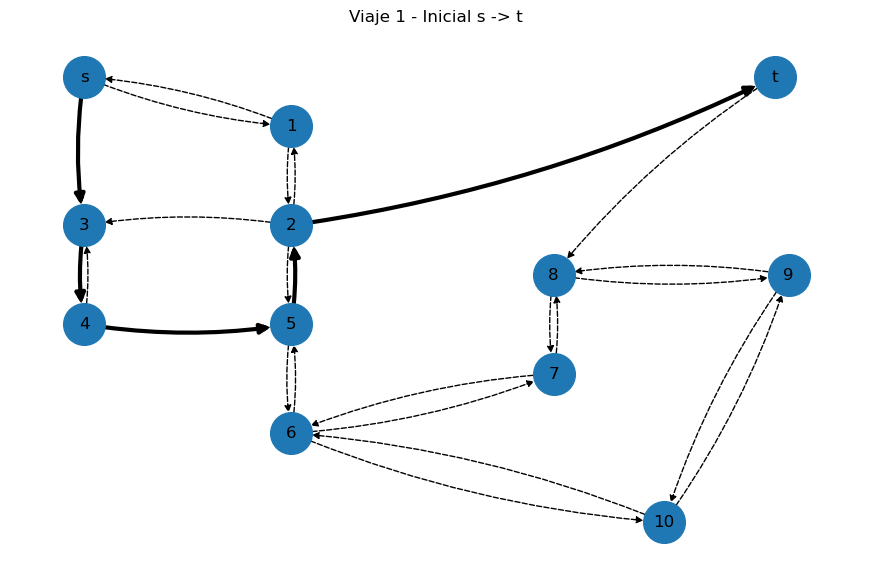

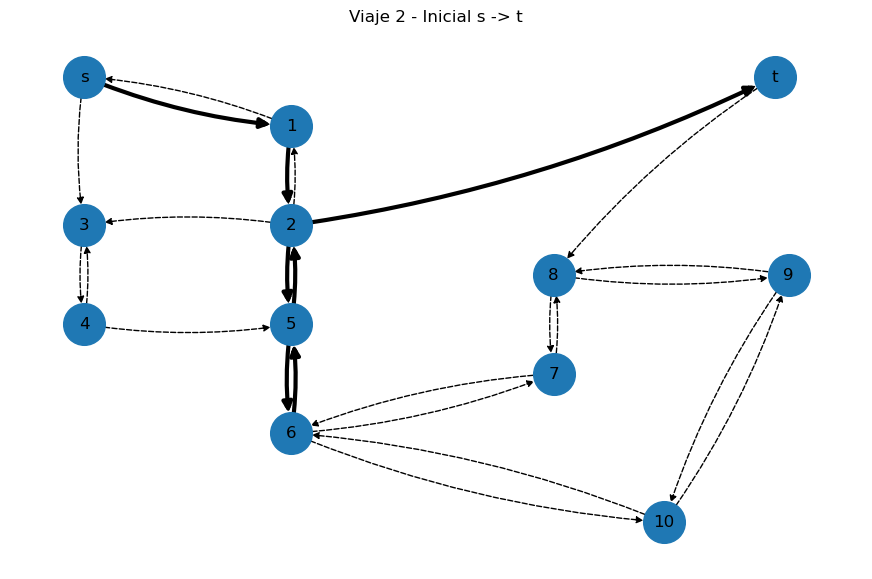

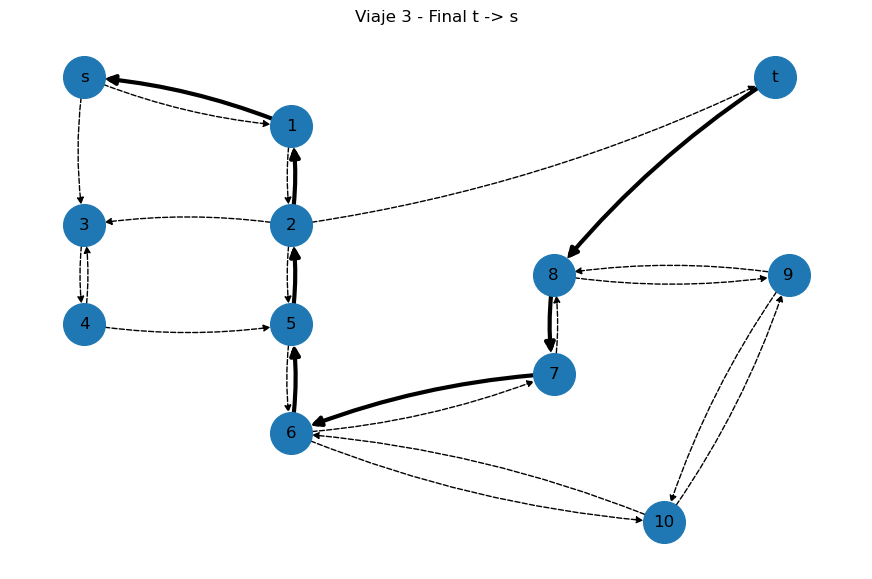

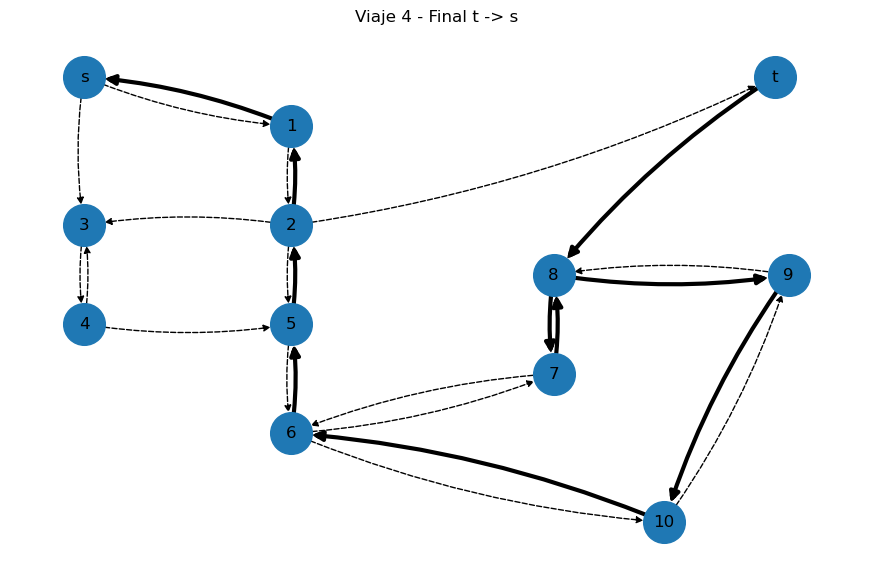

In [76]:

if model.status == GRB.Status.OPTIMAL:

    for r in R:

        arcos_r = []

        for (i,j) in A:

            veces = int(round(y[r,i,j].X))

            if (i,j) in AR and x[r,i,j].X > 0.5:
                veces += 1

            if veces > 0:
                arcos_r.append((i,j))

        plt.figure(figsize=(11,7))

        nx.draw_networkx_nodes(D, pos, node_size=900)
        nx.draw_networkx_labels(D, pos)

        nx.draw_networkx_edges(
            D, pos,
            edgelist=A,
            arrows=True,
            node_size=900,
            arrowsize=10,
            width=1,
            style="dashed",
            connectionstyle="arc3,rad=0.08"
        )

        nx.draw_networkx_edges(
            D, pos,
            edgelist=arcos_r,
            arrows=True,
            node_size=900,
            arrowsize=14,
            width=3,
            connectionstyle="arc3,rad=0.08"
        )

        if r in R_iniciales:
            tipo = "Inicial s -> t"
        elif r in R_finales:
            tipo = "Final t -> s"
        else:
            tipo = "Intermedio t -> t"

        plt.title("Viaje {} - {}".format(r,tipo))
        plt.axis("off")
        plt.show()
